# oi-vector-bench results

Filtered, grouped and diversified vector search in Postgres 18: **pgvector HNSW** vs
**pg_vectorsearch PRISM**, with an exact (GIN / seq scan) baseline, on 1M Open Images
images embedded with two models:

| key | model | dim | results dir | PRISM fastscan |
|---|---|---|---|---|
| `pe` | PE-Core-L14-336 | 1024 | `results/m1-a` | off (dimension limit) |
| `clip` | OpenAI CLIP ViT-L/14@336 | 768 | `results/c1-a` | on |

Each row of `scored.csv` is one query under one config, already scored against exact
ground truth by `oibench report`. Run from the repo root:

```bash
uv sync --extra bench --extra analysis
uv run --extra bench --extra analysis jupyter lab notebooks/results.ipynb
```

**Vocabulary** 

* *Forced* mode disables seq/bitmap scans and sorts, so only the vector
index can answer.
* *Planner* mode lets Postgres choose (often the exact GIN plan for
selective filters).
* *Selectivity* is the share of items carrying the filter label.
* *Lift* is how much more common the label is among the query's 1,000 nearest
neighbours than in the whole set: lift < 1 means the matching items sit away from the
query, which is where post-filtering indexes run out of candidates.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = {"pe": ROOT / "results/m1-a", "clip": ROOT / "results/c1-a"}

# Method families keep one colour everywhere (validated categorical slots 1-3);
# planner mode is dashed so colour never carries the distinction alone.
FAMILY_COLOR = {"hnsw": "#2a78d6", "prism": "#eb6834", "hnsw_iter": "#1baf7a", "exact": "#6b6a64"}
MODE_STYLE = {"forced": "-", "planner": "--"}
MODE_MARKER = {"forced": "o", "planner": "s"}

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8d8c85",
        "axes.labelcolor": "#3d3c37",
        "xtick.color": "#5d5c55",
        "ytick.color": "#5d5c55",
        "lines.linewidth": 2,
        "lines.markersize": 6,
        "legend.frameon": False,
        "font.size": 9,
    }
)

In [2]:
SEL_ORDER = [
    "3e-01-1e+00",
    "1e-01-3e-01",
    "3e-02-1e-01",
    "1e-02-3e-02",
    "3e-03-1e-02",
    "1e-03-3e-03",
    "3e-04-1e-03",
    "1e-04-3e-04",
    "3e-05-1e-04",
    "1e-05-3e-05",
]
SEL_LABEL = dict(
    zip(
        SEL_ORDER,
        [
            "30–100%",
            "10–30%",
            "3–10%",
            "1–3%",
            "0.3–1%",
            "0.1–0.3%",
            "0.03–0.1%",
            "0.01–0.03%",
            "0.003–0.01%",
            "0.001–0.003%",
        ],
        strict=True,
    )
)
LIFT_EDGES = [-np.inf, 0.1, 0.3, 1, 3, 10, np.inf]
LIFT_LABELS = ["<0.1", "0.1–0.3", "0.3–1", "1–3", "3–10", ">10"]
BAND_ORDER = ["broad ≥1%", "mid 0.1–1%", "narrow <0.1%"]


def short_settings(g: str) -> str:
    return (
        g.replace("hnsw.", "")
        .replace("prism.", "")
        .replace("iterative_scan", "iter")
        .replace("ef_search", "ef")
        .replace("max_scan_tuples", "tuples")
        .replace("enable_indexscan=off", "GIN / seq scan")
    )


def load(model: str, path: Path) -> pd.DataFrame:
    s = pd.read_csv(path / "scored.csv", low_memory=False)
    s["model"] = model
    for c in ("k", "G", "cap"):
        s[c] = pd.to_numeric(s[c], errors="coerce")
    s["settings"] = s.gucs_s.map(short_settings)
    s["config"] = s.method + " | " + s["mode"] + " | " + s.settings
    s["sel_band"] = np.select([s.selectivity >= 0.01, s.selectivity >= 0.001], BAND_ORDER[:2], BAND_ORDER[2])
    s["lift_b"] = pd.cut(s.lift, LIFT_EDGES, labels=LIFT_LABELS)
    return s


S = pd.concat([load(m, p) for m, p in RESULTS.items() if (p / "scored.csv").exists()], ignore_index=True)
F = S[S.kind == "filter"]
print(f"{len(S):,} scored rows, models: {sorted(S.model.unique())}, errors: {int(S.error.sum())}")
S.groupby(["model", "method", "mode"]).config.nunique().unstack("model").rename_axis(columns="configs per model")

193,731 scored rows, models: ['clip', 'pe'], errors: 0


configs per model  clip   pe
method    mode              
exact     planner   1.0  1.0
hnsw      forced    3.0  4.0
          planner   3.0  3.0
hnsw_iter forced    NaN  4.0
          planner   NaN  4.0
prism     forced    4.0  4.0
          planner   4.0  4.0

In [3]:
# Configs used in the plots: one representative per family and mode. Edit freely.
KEY = [
    "exact | planner | GIN / seq scan",
    "hnsw | forced | ef=100,iter=off",
    "hnsw | planner | ef=100,iter=off",
    "hnsw_iter | forced | ef=40,iter=relaxed_order,tuples=200000",
    "hnsw_iter | planner | ef=40,iter=relaxed_order,tuples=200000",
    "prism | forced | nprobe=0",
    "prism | planner | nprobe=0",
    "prism | forced | nprobe=256",
]


def style(config: str) -> dict:
    method, mode, settings = config.split(" | ")
    kw = dict(color=FAMILY_COLOR[method], linestyle=MODE_STYLE[mode], marker=MODE_MARKER[mode])
    if method == "prism" and "256" in settings:
        kw["alpha"] = 0.55  # same family, the high-nprobe variant
    return kw


def recall_gradient(df: pd.DataFrame):
    return df.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None).format("{:.2f}", na_rep="")

## 1. Filters by selectivity

Recall@k for every config, by label selectivity (columns, broad → narrow). Change
`MODEL`, `K`, `FTYPE` (`pos` = query image has the label, `rand` = unrelated,
`neg` = verified absent) or `VALUE` (`recall`, `short`, `latency_ms`).

In [4]:
MODEL, K, FTYPE, VALUE = "pe", 10, "rand", "recall"

d = F[(F.model == MODEL) & (F.k == K) & (F.ftype == FTYPE)]
agg = "median" if VALUE == "latency_ms" else "mean"
p = d.pivot_table(index="config", columns="bin", values=VALUE, aggfunc=agg)
p = p[[b for b in SEL_ORDER if b in p.columns]].rename(columns=SEL_LABEL)
recall_gradient(p) if VALUE != "latency_ms" else p.round(1)

bin,30–100%,10–30%,3–10%,1–3%,0.3–1%,0.1–0.3%,0.03–0.1%,0.01–0.03%,0.003–0.01%,0.001–0.003%
config,,,,,,,,,,
exact | planner | GIN / seq scan,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
"hnsw | forced | ef=100,iter=off",0.44,0.34,0.23,0.09,0.04,0.01,0.00,0.00,0.00,0.00
"hnsw | forced | ef=40,iter=off",0.32,0.23,0.14,0.04,0.02,0.00,0.00,0.00,0.00,0.00
"hnsw | forced | ef=40,iter=relaxed_order",0.93,0.89,0.88,0.69,0.60,0.35,0.20,0.10,0.08,0.01
"hnsw | forced | ef=400,iter=off",0.69,0.57,0.40,0.22,0.09,0.02,0.01,0.00,0.00,0.00
"hnsw | planner | ef=100,iter=off",0.44,0.34,0.23,0.09,0.06,0.94,1.00,1.00,1.00,1.00
"hnsw | planner | ef=40,iter=off",0.32,0.23,0.14,0.04,0.04,0.92,1.00,1.00,1.00,1.00
"hnsw | planner | ef=400,iter=off",0.69,0.57,0.40,0.22,0.19,1.00,1.00,1.00,1.00,1.00
"hnsw_iter | forced | ef=40,iter=relaxed_order,tuples=20000",0.93,0.89,0.88,0.69,0.60,0.35,0.20,0.10,0.08,0.01


## 2. Lift is what decides failure

Same queries, grouped by lift instead of filter type. For broad filters the planner
always uses the vector index, so whatever happens here is what an application gets.

In [5]:
def lift_table(model: str, k: int = 10):
    # returns (query counts per cell, recall per KEY config) for one model
    d = F[(F.model == model) & (F.k == k)]
    n = d[d.config == KEY[0]].groupby(["sel_band", "lift_b"], observed=True).size().rename("n queries").to_frame().T
    p = d.pivot_table(index="config", columns=["sel_band", "lift_b"], values="recall", aggfunc="mean", observed=True)
    return n, p.reindex([c for c in KEY if c in p.index])


n, p = lift_table("pe")
display(n)
recall_gradient(p)

sel_band  broad ≥1%                             mid 0.1–1%                             narrow <0.1%              
lift_b         <0.1 0.1–0.3 0.3–1  1–3 3–10 >10       <0.1 0.1–0.3 0.3–1 1–3 3–10  >10         <0.1 1–3 3–10  >10
n queries       127      61   104  138  115  55         82      17    32  33   33  103          261  12   25  302

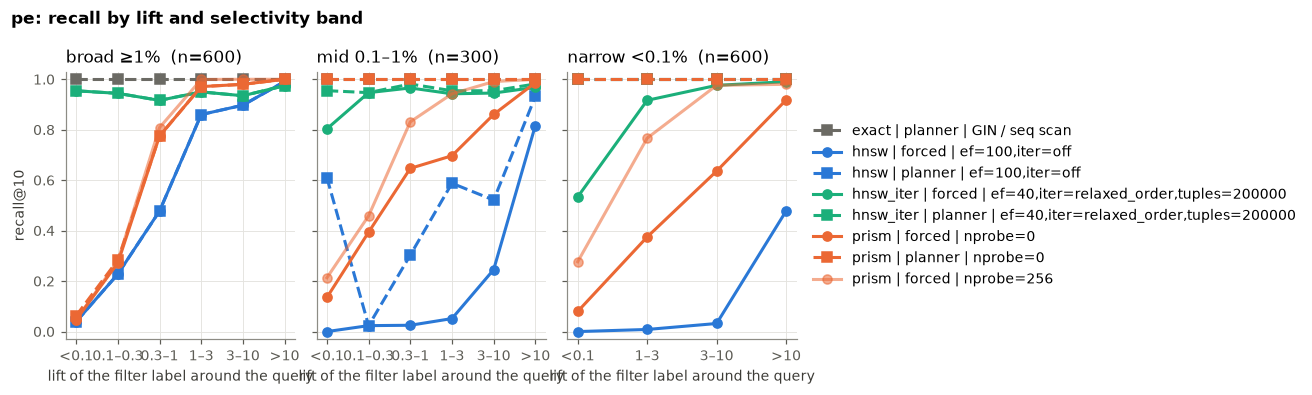

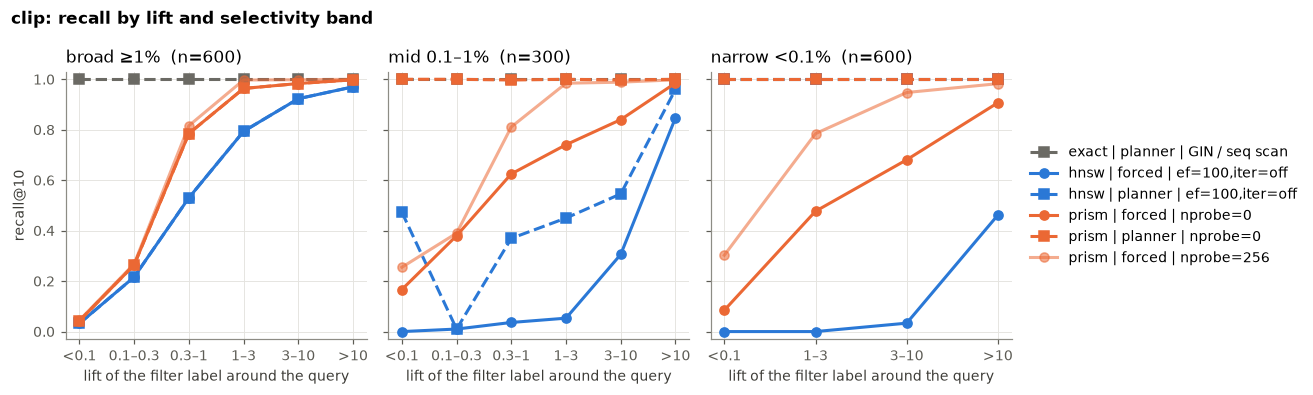

In [6]:
def plot_lift(model: str, k: int = 10):
    d = F[(F.model == model) & (F.k == k) & F.config.isin(KEY)]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for ax, band in zip(axes, BAND_ORDER, strict=True):
        b = d[d.sel_band == band]
        g = b.groupby(["config", "lift_b"], observed=True).recall.mean().unstack()
        g = g[[c for c in LIFT_LABELS if c in g.columns]]
        x = np.arange(len(g.columns))
        for config in [c for c in KEY if c in g.index]:
            ax.plot(x, g.loc[config].values, label=config, **style(config))
        ax.set_xticks(x, g.columns)
        ax.set_title(f"{band}  (n={b[b.config == KEY[0]].shape[0]})", loc="left")
        ax.set_xlabel("lift of the filter label around the query")
        ax.set_ylim(-0.03, 1.03)
    axes[0].set_ylabel(f"recall@{k}")
    fig.suptitle(f"{model}: recall by lift and selectivity band", x=0.01, ha="left", fontweight="bold")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig


for model in S.model.unique():
    plot_lift(model)

## 3. Where the planner takes over

Recall by selectivity for `rand` and `neg` filters. Dashed lines are planner mode:
the jump to 1.0 in the narrow bins is Postgres switching to the exact GIN plan.

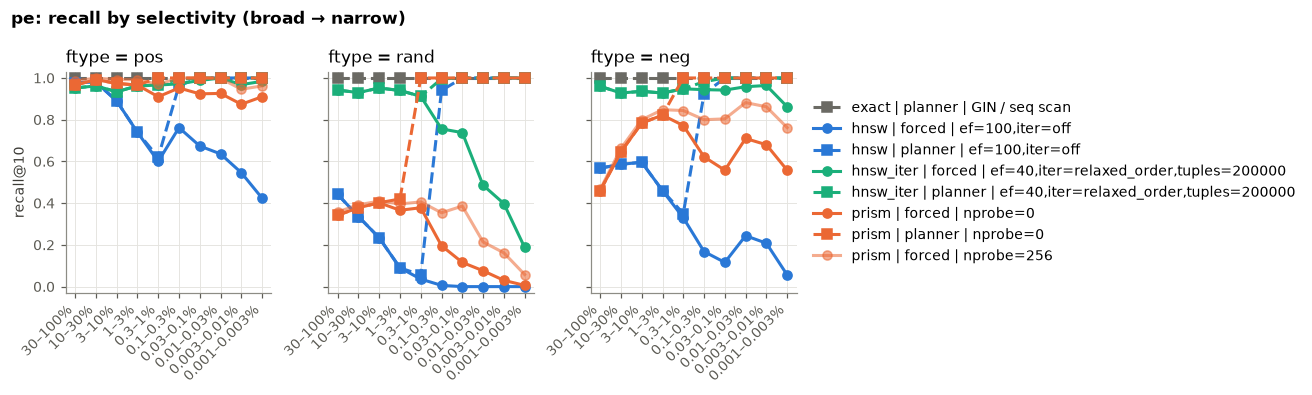

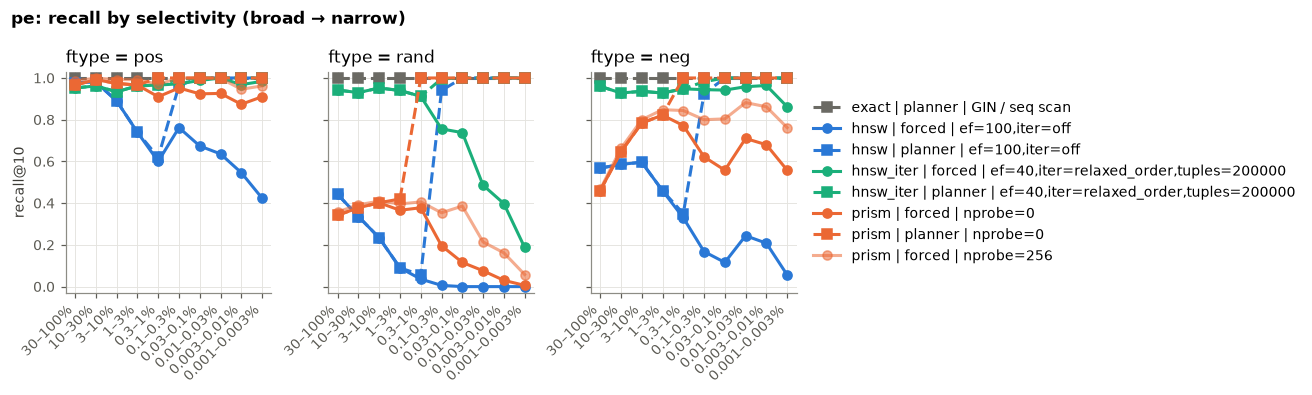

In [7]:
def plot_selectivity(model: str, k: int = 10):
    d = F[(F.model == model) & (F.k == k) & F.config.isin(KEY)]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for ax, ftype in zip(axes, ["pos", "rand", "neg"], strict=True):
        g = d[d.ftype == ftype].groupby(["config", "bin"]).recall.mean().unstack()
        g = g[[b for b in SEL_ORDER if b in g.columns]]
        x = np.arange(len(g.columns))
        for config in [c for c in KEY if c in g.index]:
            ax.plot(x, g.loc[config].values, label=config, **style(config))
        ax.set_xticks(x, [SEL_LABEL[b] for b in g.columns], rotation=45, ha="right")
        ax.set_title(f"ftype = {ftype}", loc="left")
        ax.set_ylim(-0.03, 1.03)
    axes[0].set_ylabel(f"recall@{k}")
    fig.suptitle(f"{model}: recall by selectivity (broad → narrow)", x=0.01, ha="left", fontweight="bold")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig


plot_selectivity("pe")

## 4. Recall vs latency

One point per config (all of them, not just `KEY`): mean recall@10 against median
latency over the filter queries in each band. Up and to the left is better; the exact
baseline is the grey square.

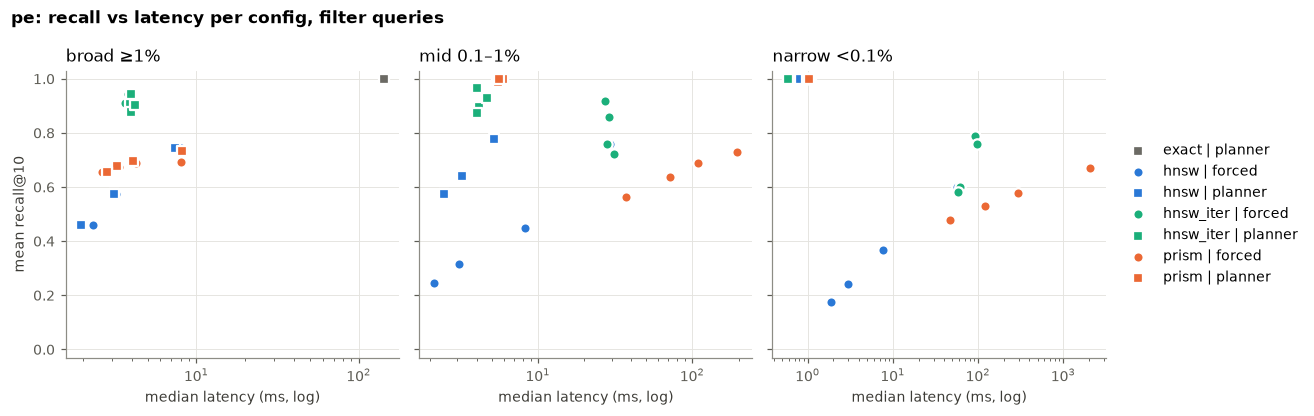

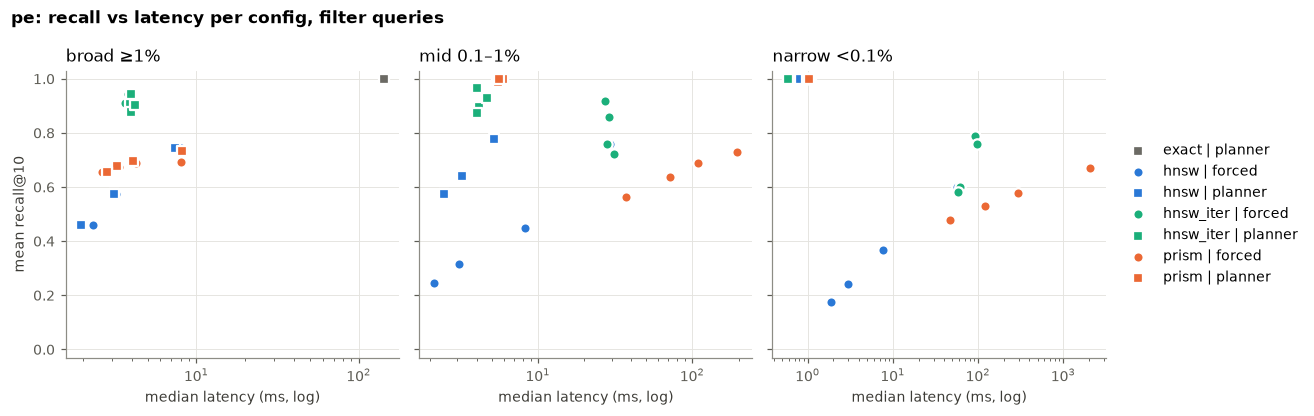

In [8]:
def plot_tradeoff(model: str, k: int = 10):
    d = F[(F.model == model) & (F.k == k)]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
    for ax, band in zip(axes, BAND_ORDER, strict=True):
        g = (
            d[d.sel_band == band]
            .groupby(["config", "method", "mode"])
            .agg(recall=("recall", "mean"), latency=("latency_ms", "median"))
            .reset_index()
        )
        for (method, mode), sub in g.groupby(["method", "mode"]):
            ax.scatter(
                sub.latency,
                sub.recall,
                s=46,
                color=FAMILY_COLOR[method],
                marker=MODE_MARKER[mode],
                edgecolor="white",
                linewidth=1.5,
                label=f"{method} | {mode}",
                zorder=3,
            )
        ax.set_xscale("log")
        ax.set_title(band, loc="left")
        ax.set_xlabel("median latency (ms, log)")
        ax.set_ylim(-0.03, 1.03)
    axes[0].set_ylabel(f"mean recall@{k}")
    fig.suptitle(f"{model}: recall vs latency per config, filter queries", x=0.01, ha="left", fontweight="bold")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig


plot_tradeoff("pe")

## 5. Grouping and diversity

Grouping: top-3 per label for G labels; `lateral` runs one filtered subquery per
label, `overfetch:M` takes the unfiltered top-M and groups it. Diversity: top-k with at
most `cap` images per photographer. Averaged over selectivity bins.

In [9]:
G = S[S.kind == "group_label"]
recall_gradient(G.pivot_table(index="config", columns=["model", "strategy", "G"], values="recall", aggfunc="mean"))

In [10]:
D = S[S.kind == "diverse"]
p = D.pivot_table(index="config", columns=["model", "strategy", "k", "cap"], values="recall", aggfunc="mean")
recall_gradient(p)

## 6. PE-Core vs CLIP

Same images, labels and query images; different embeddings. If the two models agree,
the behaviour belongs to the index, not the model. The latency ratio also shows what
PRISM's fastscan (on for CLIP only) buys, against HNSW's change from 1024 to 768 dims.

In [11]:
both = (
    F[F.k == 10].groupby(["config", "model"]).agg(recall=("recall", "mean"), latency=("latency_ms", "median")).unstack()
)
both = both.dropna()
cmp = pd.DataFrame(
    {
        "recall pe": both[("recall", "pe")],
        "recall clip": both[("recall", "clip")],
        "latency pe (ms)": both[("latency", "pe")],
        "latency clip (ms)": both[("latency", "clip")],
    }
)
cmp["clip / pe latency"] = cmp["latency clip (ms)"] / cmp["latency pe (ms)"]
cmp.round(3)

,recall pe,recall clip,latency pe (ms),latency clip (ms),clip / pe latency
config,,,,,
exact | planner | GIN / seq scan,1.000,1.000,5.768,5.333,0.925
"hnsw | forced | ef=100,iter=off",0.390,0.383,3.068,2.697,0.879
"hnsw | forced | ef=40,iter=off",0.304,0.298,2.070,1.906,0.921
"hnsw | forced | ef=400,iter=off",0.535,0.521,7.914,6.608,0.835
"hnsw | planner | ef=100,iter=off",0.758,0.749,2.431,2.367,0.974
"hnsw | planner | ef=40,iter=off",0.699,0.692,1.764,1.414,0.802
"hnsw | planner | ef=400,iter=off",0.853,0.840,4.244,4.047,0.954
prism | forced | nprobe=0,0.610,0.605,59.791,54.570,0.913
prism | forced | nprobe=16,0.566,0.561,23.841,21.264,0.892


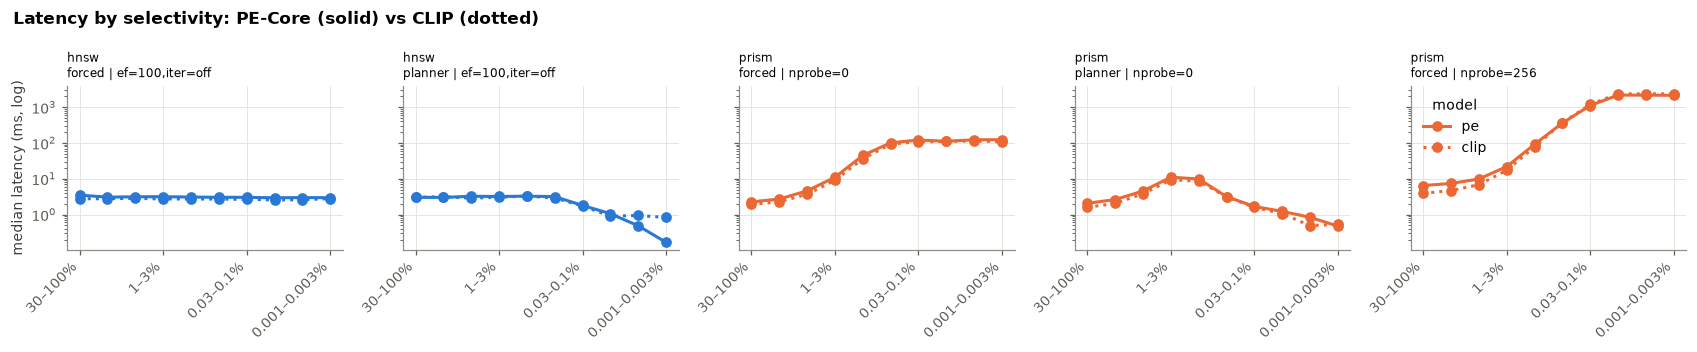

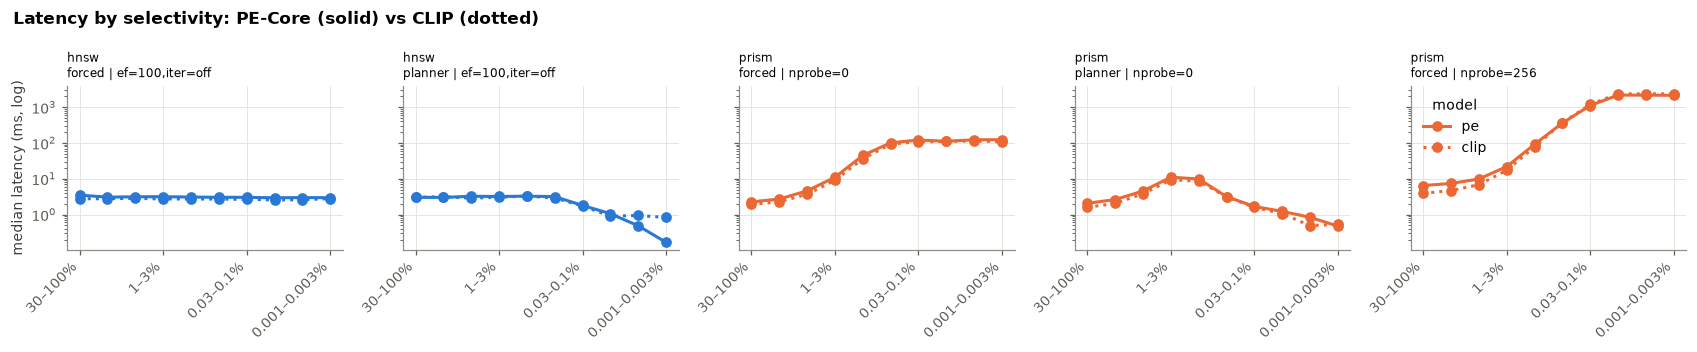

In [12]:
def plot_model_latency(k: int = 10):
    configs = [c for c in KEY if c.split(" | ")[0] in ("hnsw", "prism")]
    d = F[(F.k == k) & F.config.isin(configs)]
    fig, axes = plt.subplots(1, len(configs), figsize=(3.1 * len(configs), 3.2), sharey=True)
    for ax, config in zip(axes, configs, strict=True):
        g = d[d.config == config].groupby(["model", "bin"]).latency_ms.median().unstack()
        g = g[[b for b in SEL_ORDER if b in g.columns]]
        x = np.arange(len(g.columns))
        for model, ls in (("pe", "-"), ("clip", ":")):
            if model in g.index:
                ax.plot(
                    x,
                    g.loc[model].values,
                    linestyle=ls,
                    label=model,
                    color=FAMILY_COLOR[config.split(" | ")[0]],
                    marker="o",
                )
        ax.set_yscale("log")
        ax.set_xticks(x[::3], [SEL_LABEL[b] for b in g.columns][::3], rotation=45, ha="right")
        ax.set_title(config.replace(" | ", "\n", 1), loc="left", fontsize=8)
    axes[0].set_ylabel("median latency (ms, log)")
    axes[-1].legend(title="model")
    fig.suptitle("Latency by selectivity: PE-Core (solid) vs CLIP (dotted)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    return fig


plot_model_latency()